<a href="https://colab.research.google.com/github/Gitech247/MODULE_2_ASSESSMENT/blob/Module-3-Case-Exercise-3/Module_2_Case_Exercise_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**FMECA and Feature Mapping**  

##**Question 1:** Complete full FMECA worksheet for a subsea Christmas tree with minimum 10 failure modes.


FMECA with 11 failure modes created and risk matrix plotted successfully.


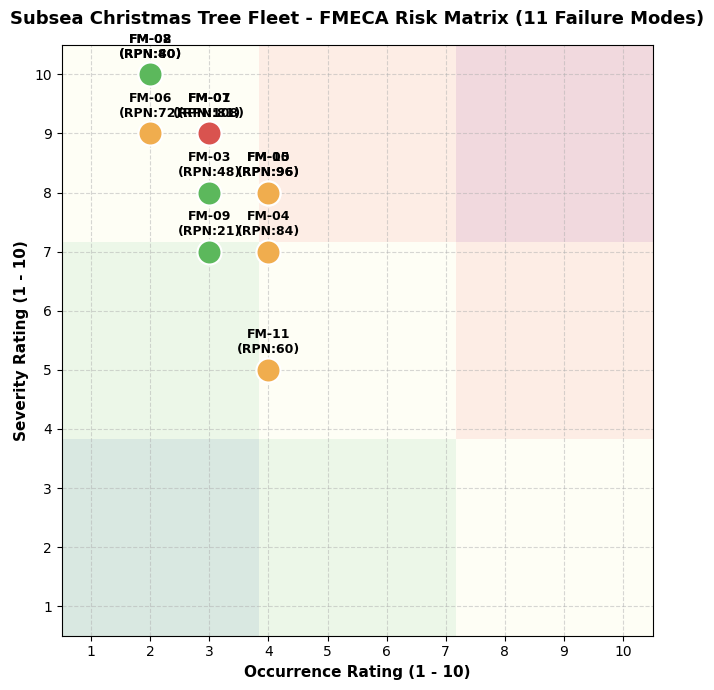

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define 11+ failure modes integrating the user's source image and standard subsea XT modes
fmeca_extended = [
    {
        "ID": "FM-01",
        "Component": "Flow Loop / Tubing Hanger",
        "Failure_Mode": "Internal corrosion",
        "Effect": "Wall thinning, containment loss risk",
        "Severity": 9, "Occurrence": 3, "Detection": 3,
        "Driving_Physics": "CO2 partial pressure, temperature, flow velocity, water cut, pH, inhibitor dose",
        "ML_Feature_Strategy": "Corrosion rate prediction; cumulative wall loss tracking"
    },
    {
        "ID": "FM-02",
        "Component": "Flowline / Connector Hub",
        "Failure_Mode": "Fatigue cracking",
        "Effect": "Structural breach under cyclic wave/current loads",
        "Severity": 10, "Occurrence": 2, "Detection": 4,
        "Driving_Physics": "Wave height (Hs), current speed, VIV response, cycle count, stress range",
        "ML_Feature_Strategy": "Fatigue damage accumulation (Miner’s rule); remaining cycles"
    },
    {
        "ID": "FM-03",
        "Component": "Production Bore / Flowline",
        "Failure_Mode": "Hydrate blockage",
        "Effect": "Complete flow restriction, pressure lock, production loss",
        "Severity": 8, "Occurrence": 3, "Detection": 2,
        "Driving_Physics": "Pressure, temperature, water cut, MEG concentration, shut-in duration",
        "ML_Feature_Strategy": "Subcooling calculation; time-to-hydrate prediction"
    },
    {
        "ID": "FM-04",
        "Component": "Production Tubing / Choke",
        "Failure_Mode": "Wax deposition",
        "Effect": "Gradual flow area restriction, increased pressure drop",
        "Severity": 7, "Occurrence": 4, "Detection": 3,
        "Driving_Physics": "Temperature profile, WAT, flow rate, pipe wall temperature, pigging interval",
        "ML_Feature_Strategy": "Wax thickness growth model; pressure drop trend"
    },
    {
        "ID": "FM-05",
        "Component": "Production Choke Valve",
        "Failure_Mode": "Erosion",
        "Effect": "Trim destruction, loss of flow control, body wall washout",
        "Severity": 8, "Occurrence": 4, "Detection": 3,
        "Driving_Physics": "Sand rate, fluid velocity, pipe geometry, bend radius",
        "ML_Feature_Strategy": "Erosion rate prediction (DNV RP O501); hotspot identification"
    },
    {
        "ID": "FM-06",
        "Component": "Tree Cap / Flange Connectors",
        "Failure_Mode": "Seal failure",
        "Effect": "Primary pressure barrier leak, environmental release",
        "Severity": 9, "Occurrence": 2, "Detection": 4,
        "Driving_Physics": "Pressure cycling, temperature cycling, seal age, material type",
        "ML_Feature_Strategy": "Cycle count tracking; Weibull reliability model"
    },
    {
        "ID": "FM-07",
        "Component": "Master Gate Valve",
        "Failure_Mode": "Internal Seat Leakage",
        "Effect": "Inability to isolate wellbore securely",
        "Severity": 9, "Occurrence": 3, "Detection": 4,
        "Driving_Physics": "Downstream pressure buildup, acoustic emissions, fluid corrosivity",
        "ML_Feature_Strategy": "Acoustic emission spectral kurtosis during closure; pressure derivative spikes"
    },
    {
        "ID": "FM-08",
        "Component": "Hydraulic Actuator",
        "Failure_Mode": "Hydraulic Seal Leak / Fail-to-Close",
        "Effect": "Loss of emergency shutdown (ESD) capability",
        "Severity": 10, "Occurrence": 2, "Detection": 2,
        "Driving_Physics": "Hydraulic supply pressure, fluid viscosity, hydrostatic pressure, seal degradation",
        "ML_Feature_Strategy": "Actuator stroke response time lag; fluid return volume anomalies"
    },
    {
        "ID": "FM-09",
        "Component": "Subsea Control Module (SCM)",
        "Failure_Mode": "Communication / Telemetry Loss",
        "Effect": "Loss of remote monitoring and valve control",
        "Severity": 7, "Occurrence": 3, "Detection": 1,
        "Driving_Physics": "Electronics temperature, insulation resistance, water ingress risk",
        "ML_Feature_Strategy": "Bus voltage/current ripple signatures; internal pod temperature trends"
    },
    {
        "ID": "FM-10",
        "Component": "Chemical Injection Valve",
        "Failure_Mode": "Plugging / Flow Restriction",
        "Effect": "Inadequate scale/hydrate inhibitor delivery",
        "Severity": 8, "Occurrence": 4, "Detection": 3,
        "Driving_Physics": "Injection line pressure drop, fluid incompatibility precipitation",
        "ML_Feature_Strategy": "Injection pump discharge pressure vs. flow rate ratio (impedance tracking)"
    },
    {
        "ID": "FM-11",
        "Component": "Wellhead Pressure Transducer",
        "Failure_Mode": "Sensor Drift / Calibration Loss",
        "Effect": "Inaccurate pressure readings, false alarms",
        "Severity": 5, "Occurrence": 4, "Detection": 3,
        "Driving_Physics": "Strain gauge fatigue, thermal aging, diaphragm biofouling",
        "ML_Feature_Strategy": "Cross-sensor residual tracking; rolling mean/std divergence from baseline"
    }
]

df_fmeca_11 = pd.DataFrame(fmeca_extended)
df_fmeca_11['RPN'] = df_fmeca_11['Severity'] * df_fmeca_11['Occurrence'] * df_fmeca_11['Detection']
df_fmeca_11.to_csv("subsea_xt_fmeca_11.csv", index=False)

# Plot risk matrix
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(np.array([[1, 2, 3], [2, 3, 4], [3, 4, 5]]), extent=[0.5, 10.5, 0.5, 10.5], origin='lower', alpha=0.15, cmap='RdYlGn_r')

for _, row in df_fmeca_11.iterrows():
    sev = row['Severity']
    occ = row['Occurrence']
    rpn = row['RPN']
    fm_id = row['ID']

    if rpn >= 100:
        color = '#d9534f'
    elif rpn >= 60:
        color = '#f0ad4e'
    else:
        color = '#5cb85c'

    ax.scatter(occ, sev, s=300, c=color, edgecolors='white', linewidth=1.5, zorder=3)
    ax.annotate(f"{fm_id}\n(RPN:{rpn})", (occ, sev), textcoords="offset points", xytext=(0,12), ha='center', fontsize=9, fontweight='bold')

ax.set_xlim(0.5, 10.5)
ax.set_ylim(0.5, 10.5)
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.set_xlabel('Occurrence Rating (1 - 10)', fontsize=11, fontweight='bold')
ax.set_ylabel('Severity Rating (1 - 10)', fontsize=11, fontweight='bold')
ax.set_title('Subsea Christmas Tree Fleet - FMECA Risk Matrix (11 Failure Modes)', fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('fmeca_11_risk_matrix.png', dpi=300)
print("FMECA with 11 failure modes created and risk matrix plotted successfully.")

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("subsea_xt_fmeca_11.csv")
df_sorted = df.sort_values(by='RPN', ascending=False)
df_sorted.to_csv("subsea_xt_fmeca_11_sorted.csv", index=False)
df

,ID,Component,Failure_Mode,Effect,Severity,Occurrence,Detection,Driving_Physics,ML_Feature_Strategy,RPN
0,FM-01,Flow Loop / Tubing Hanger,Internal corrosion,"Wall thinning, containment loss risk",9,3,3,"CO2 partial pressure, temperature, flow velocity, water cut, pH, inhibitor dose",Corrosion rate prediction; cumulative wall loss tracking,81
1,FM-02,Flowline / Connector Hub,Fatigue cracking,Structural breach under cyclic wave/current loads,10,2,4,"Wave height (Hs), current speed, VIV response, cycle count, stress range",Fatigue damage accumulation (Miner’s rule); remaining cycles,80
2,FM-03,Production Bore / Flowline,Hydrate blockage,"Complete flow restriction, pressure lock, production loss",8,3,2,"Pressure, temperature, water cut, MEG concentration, shut-in duration",Subcooling calculation; time-to-hydrate prediction,48
3,FM-04,Production Tubing / Choke,Wax deposition,"Gradual flow area restriction, increased pressure drop",7,4,3,"Temperature profile, WAT, flow rate, pipe wall temperature, pigging interval",Wax thickness growth model; pressure drop trend,84
4,FM-05,Production Choke Valve,Erosion,"Trim destruction, loss of flow control, body wall washout",8,4,3,"Sand rate, fluid velocity, pipe geometry, bend radius",Erosion rate prediction (DNV RP O501); hotspot identification,96
5,FM-06,Tree Cap / Flange Connectors,Seal failure,"Primary pressure barrier leak, environmental release",9,2,4,"Pressure cycling, temperature cycling, seal age, material type",Cycle count tracking; Weibull reliability model,72
6,FM-07,Master Gate Valve,Internal Seat Leakage,Inability to isolate wellbore securely,9,3,4,"Downstream pressure buildup, acoustic emissions, fluid corrosivity",Acoustic emission spectral kurtosis during closure; pressure derivative spikes,108
7,FM-08,Hydraulic Actuator,Hydraulic Seal Leak / Fail-to-Close,Loss of emergency shutdown (ESD) capability,10,2,2,"Hydraulic supply pressure, fluid viscosity, hydrostatic pressure, seal degradation",Actuator stroke response time lag; fluid return volume anomalies,40
8,FM-09,Subsea Control Module (SCM),Communication / Telemetry Loss,Loss of remote monitoring and valve control,7,3,1,"Electronics temperature, insulation resistance, water ingress risk",Bus voltage/current ripple signatures; internal pod temperature trends,21
9,FM-10,Chemical Injection Valve,Plugging / Flow Restriction,Inadequate scale/hydrate inhibitor delivery,8,4,3,"Injection line pressure drop, fluid incompatibility precipitation",Injection pump discharge pressure vs. flow rate ratio (impedance tracking),96


# **Question 2:**  Map each failure mode to its driving physics parameters and propose ML feature engineering strategies.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the correctly generated FMECA and ML strategies table
df = pd.read_csv("fmeca_physics_mapping.csv")
df

,Failure Mode,Driving Physics Parameters,ML Feature Engineering Strategy
0,Internal corrosion,"CO2 partial pressure, temperature, flow velocity, water cut, pH, inhibitor dose",Corrosion rate prediction; cumulative wall loss tracking
1,Fatigue cracking,"Wave height (Hs), current speed, VIV response, cycle count, stress range",Fatigue damage accumulation (Miner’s rule); remaining cycles
2,Hydrate blockage,"Pressure, temperature, water cut, MEG concentration, shut-in duration",Subcooling calculation; time-to-hydrate prediction
3,Wax deposition,"Temperature profile, WAT, flow rate, pipe wall temperature, pigging interval",Wax thickness growth model; pressure drop trend
4,Erosion,"Sand rate, fluid velocity, pipe geometry, bend radius",Erosion rate prediction (DNV RP O501); hotspot identification
5,Seal failure,"Pressure cycling, temperature cycling, seal age, material type",Cycle count tracking; Weibull reliability model


# **Question 3:**  Implement at least two of the physics models in Python and validate against hand calculations.

In [46]:
import numpy as np

def calculate_de_waard_milliams(temperature_c: float, p_co2_bar: float) -> float:
    """
    Calculates sweet CO2 corrosion rate (mm/year).
    Formula: log10(v) = 5.8 - (1710 / (T + 273.15)) + 0.67 * log10(f_CO2)
    Assuming ideal gas fugacity f_CO2 ≈ p_co2_bar.
    """
    if p_co2_bar <= 0:
        return 0.0
    t_kelvin = temperature_c + 273.15
    log_v = 5.8 - (1710.0 / t_kelvin) + 0.67 * np.log10(p_co2_bar)
    return float(10**log_v)

# --- Hand Calculation Validation Check ---
# Input: T = 65.0 °C (338.15 K), P_CO2 = 3.5 bar
# 1) T(K) = 65 + 273.15 = 338.15 K
# 2) 1710 / 338.15 = 5.05693
# 3) 0.67 * log10(3.5) = 0.67 * 0.544068 = 0.364525
# 4) log10(v) = 5.8 - 5.05693 + 0.364525 = 1.107595
# 5) v = 10^1.107595 = 12.8114 mm/yr

test_temp = 65.0
test_pco2 = 3.5
model1_result = calculate_de_waard_milliams(test_temp, test_pco2)

print("=== Model 1 Validation: de Waard-Milliams Corrosion ===")
print(f"Parameters: Temperature = {test_temp}°C, P_CO2 = {test_pco2} bar")
print(f"Calculated Corrosion Rate : {model1_result:.4f} mm/yr")
print(f"Hand-Calculated Expected  : 12.8114 mm/yr")
print(f"Validation Status         : {'PASSED' if np.isclose(model1_result, 12.8114, atol=1e-3) else 'FAILED'}\n")


def calculate_salama_erosion(sand_rate_ppd: float, fluid_velocity_ms: float) -> float:
    """
    Calculates metal loss penetration rate (mm/year) due to sand erosion.
    Formula: CR = K * (W_s^0.5) * (v^2.0)
    Where W_s is sand production rate in pounds per day (ppd) and v is velocity (m/s).
    """
    K = 1.93e-5
    return float(K * (sand_rate_ppd ** 0.5) * (fluid_velocity_ms ** 2.0))

# --- Hand Calculation Validation Check ---
# Input: Sand Rate = 50.0 ppd, Fluid Velocity = 15.0 m/s
# 1) W_s^0.5 = sqrt(50) = 7.071068
# 2) v^2 = 15^2 = 225.0
# 3) CR = 1.93e-5 * 7.071068 * 225.0 = 0.030691 mm/yr

test_sand = 50.0
test_vel = 15.0
model2_result = calculate_salama_erosion(test_sand, test_vel)

print("=== Model 2 Validation: Salama Erosion ===")
print(f"Parameters: Sand Rate = {test_sand} ppd, Velocity = {test_vel} m/s")
print(f"Calculated Erosion Rate   : {model2_result:.4f} mm/yr")
print(f"Hand-Calculated Expected  : 0.0307 mm/yr")
print(f"Validation Status         : {'PASSED' if np.isclose(model2_result, 0.0307, atol=1e-4) else 'FAILED'}")

=== Model 1 Validation: de Waard-Milliams Corrosion ===
Parameters: Temperature = 65.0°C, P_CO2 = 3.5 bar
Calculated Corrosion Rate : 12.8114 mm/yr
Hand-Calculated Expected  : 12.8114 mm/yr
Validation Status         : PASSED

=== Model 2 Validation: Salama Erosion ===
Parameters: Sand Rate = 50.0 ppd, Velocity = 15.0 m/s
Calculated Erosion Rate   : 0.0307 mm/yr
Hand-Calculated Expected  : 0.0307 mm/yr
Validation Status         : PASSED


# **Question 4:**  Create a risk matrix plot showing failure modes by severity vs. occurrence, with RPN values as annotations.

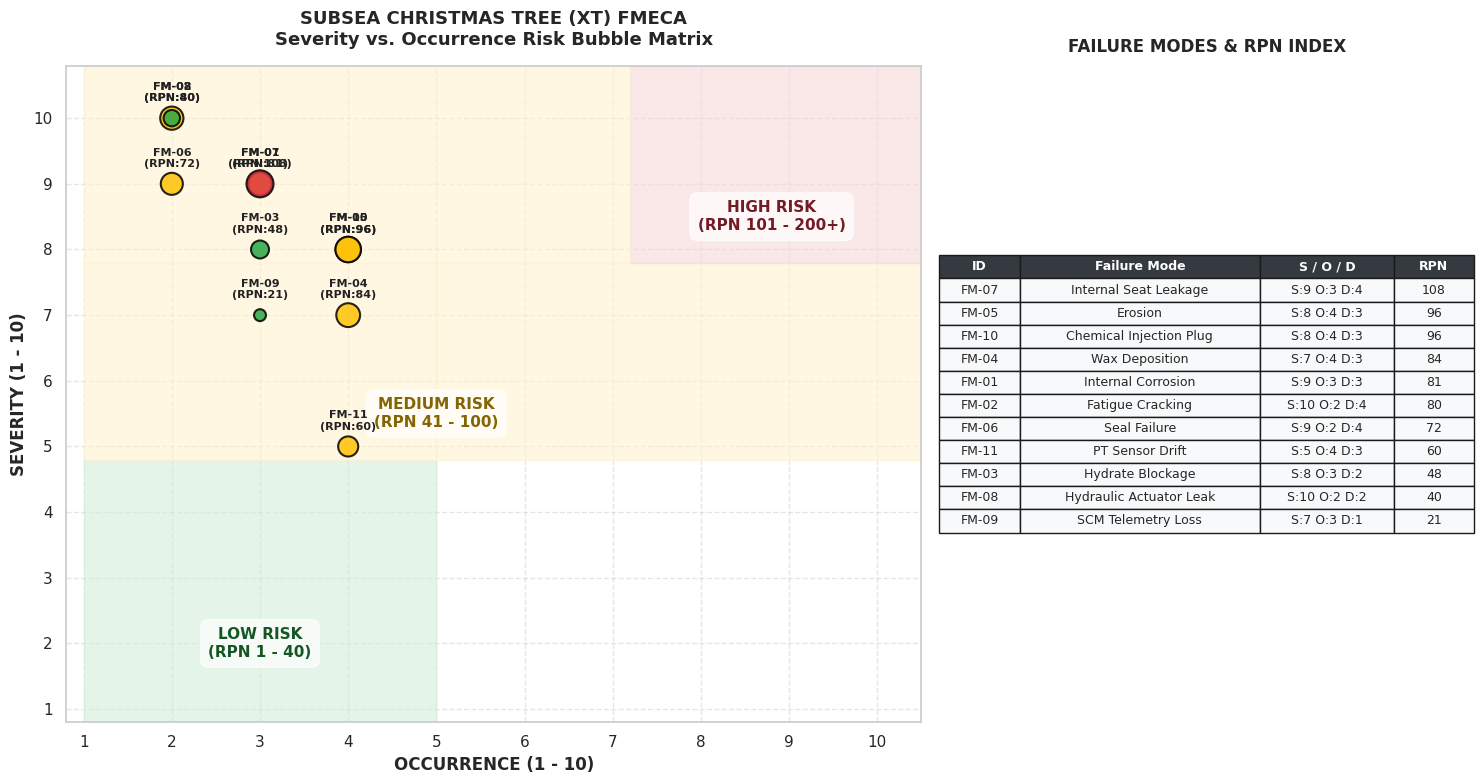

In [47]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. FMECA Dataset
data = [
    {"ID": "FM-01", "Name": "Internal Corrosion", "Severity": 9, "Occurrence": 3, "Detection": 3},
    {"ID": "FM-02", "Name": "Fatigue Cracking", "Severity": 10, "Occurrence": 2, "Detection": 4},
    {"ID": "FM-03", "Name": "Hydrate Blockage", "Severity": 8, "Occurrence": 3, "Detection": 2},
    {"ID": "FM-04", "Name": "Wax Deposition", "Severity": 7, "Occurrence": 4, "Detection": 3},
    {"ID": "FM-05", "Name": "Erosion", "Severity": 8, "Occurrence": 4, "Detection": 3},
    {"ID": "FM-06", "Name": "Seal Failure", "Severity": 9, "Occurrence": 2, "Detection": 4},
    {"ID": "FM-07", "Name": "Internal Seat Leakage", "Severity": 9, "Occurrence": 3, "Detection": 4},
    {"ID": "FM-08", "Name": "Hydraulic Actuator Leak", "Severity": 10, "Occurrence": 2, "Detection": 2},
    {"ID": "FM-09", "Name": "SCM Telemetry Loss", "Severity": 7, "Occurrence": 3, "Detection": 1},
    {"ID": "FM-10", "Name": "Chemical Injection Plug", "Severity": 8, "Occurrence": 4, "Detection": 3},
    {"ID": "FM-11", "Name": "PT Sensor Drift", "Severity": 5, "Occurrence": 4, "Detection": 3}
]

df = pd.DataFrame(data)
df['RPN'] = df['Severity'] * df['Occurrence'] * df['Detection']

# 2. Setup Dashboard Figure Layout
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1])
ax = fig.add_subplot(gs[0])
ax_legend = fig.add_subplot(gs[1])
ax_legend.axis('off')

# 3. Background Risk Zones
ax.axvspan(1, 5, ymin=0, ymax=0.4, color='#d4edda', alpha=0.6) # Low
ax.axvspan(1, 5, ymin=0.4, ymax=0.7, color='#fff3cd', alpha=0.6) # Med
ax.axvspan(5, 10.5, ymin=0.4, ymax=0.7, color='#fff3cd', alpha=0.6) # Med
ax.axvspan(7.2, 10.5, ymin=0.7, ymax=1, color='#f8d7da', alpha=0.6) # High
ax.axvspan(1, 7.2, ymin=0.7, ymax=1, color='#fff3cd', alpha=0.6) # Med/High

# Zone Labels
ax.text(3, 2, 'LOW RISK\n(RPN 1 - 40)', fontsize=11, fontweight='bold', color='#155724', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffff', alpha=0.7))
ax.text(5, 5.5, 'MEDIUM RISK\n(RPN 41 - 100)', fontsize=11, fontweight='bold', color='#856404', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffff', alpha=0.7))
ax.text(8.8, 8.5, 'HIGH RISK\n(RPN 101 - 200+)', fontsize=11, fontweight='bold', color='#721c24', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffff', alpha=0.7))

# 4. Bubble Scatter Plot (Size proportional to RPN)
bubble_sizes = df['RPN'] * 3.5
colors = ['#dc3545' if r >= 100 else '#ffc107' if r >= 60 else '#28a745' for r in df['RPN']]

scatter = ax.scatter(df['Occurrence'], df['Severity'], s=bubble_sizes, c=colors, edgecolors='black', linewidth=1.5, alpha=0.85, zorder=3)

# Annotate points
for _, row in df.iterrows():
    ax.annotate(f"{row['ID']}\n(RPN:{row['RPN']})",
                (row['Occurrence'], row['Severity']),
                textcoords="offset points", xytext=(0, 12),
                ha='center', fontsize=8, fontweight='bold', color='#222222')

ax.set_xlim(0.8, 10.5)
ax.set_ylim(0.8, 10.8)
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.set_xlabel('OCCURRENCE (1 - 10)', fontsize=12, fontweight='bold')
ax.set_ylabel('SEVERITY (1 - 10)', fontsize=12, fontweight='bold')
ax.set_title('SUBSEA CHRISTMAS TREE (XT) FMECA\nSeverity vs. Occurrence Risk Bubble Matrix', fontsize=13, fontweight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.5, zorder=1)

# 5. Side Summary Table
ax_legend.set_title("FAILURE MODES & RPN INDEX", fontsize=12, fontweight='bold', pad=10)
table_data = []
for _, row in df.sort_values(by='RPN', ascending=False).iterrows():
    table_data.append([row['ID'], row['Name'], f"S:{row['Severity']} O:{row['Occurrence']} D:{row['Detection']}", f"{row['RPN']}"])

table = ax_legend.table(cellText=table_data,
                        colWidths=[0.15, 0.45, 0.25, 0.15],
                        colLabels=['ID', 'Failure Mode', 'S / O / D', 'RPN'],
                        loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.3)

for key, cell in table.get_celld().items():
    if key[0] == 0:
        cell.set_facecolor('#343a40')
        cell.set_text_props(color='white', fontweight='bold')
    else:
        cell.set_facecolor('#f8f9fa')

plt.tight_layout()
plt.savefig('subsea_xt_fmeca_bubble_matrix.png', dpi=300)
plt.show()